# Experiment 1: efficiency as sample size increases

The correctly specified DGP is $x=u+as+v$ and $y=\beta x+u+\epsilon$. We use $a\in\{1,2,3\}$, $n\in\{200,400,\ldots,2000\}$, $\beta=1$, and 1,000 Monte Carlo replications per design point. Each value of $a$ has its own figure, with $n$ on the horizontal axis. WLS is excluded.

All methods estimate the IV and SV projections from each sample. IV-only, SV-only, and combined efficient GMM each estimate a two-step weight from their own projected first-order scores in Remark 7 and Appendix D. Because the single-channel scalar systems are exactly identified, their second-step weights do not change their point estimates.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "result" / "efficiency_replications.csv").exists():
    root = root / "unification-control-modelling"
result_dir = root / "result"
raw = pd.read_csv(result_dir / "efficiency_replications.csv")
summary = pd.read_csv(result_dir / "efficiency_summary.csv")
assert len(raw) == 600_000 and len(summary) == 600
assert set(summary["replications"]) == {1000}
methods = ["iv", "sv", "equal", "feasible_efficient"]
labels = {"iv": "IV only", "sv": "SV only", "equal": "Equal GMM", "feasible_efficient": "Efficient GMM"}
colors = {"iv": "#4477AA", "sv": "#EE6677", "equal": "#228833", "feasible_efficient": "#332288"}
markers = {"iv": "o", "sv": "s", "equal": "^", "feasible_efficient": "D"}
a_values = [1.0, 2.0, 3.0]
n_values = list(range(200, 2001, 200))
a_names = ["1", "2", "3"]


## Bias, variance, and MSE by sample size

For each method and design point, we compute bias from the mean estimate and variance with denominator $R$, where $R=1000$ is the number of replications. This makes the Monte Carlo identity **MSE = bias² + variance** exact (up to floating-point rounding). The variance and MSE panels also show the population efficient variance bound divided by $n$. Bias should fluctuate near zero; the variance reduction should drive the MSE gain.


In [2]:
est = raw[raw["scenario"] == "estimation"].copy()
est["error"] = est["beta_hat"] - est["beta"]
est["squared_error"] = est["error"] ** 2
metrics = est.groupby(["a", "n", "method"], as_index=False).agg(
    replications=("error", "size"),
    bias=("error", "mean"),
    mse=("squared_error", "mean"),
)
metrics["bias_squared"] = metrics["bias"] ** 2
metrics["variance"] = metrics["mse"] - metrics["bias_squared"]
assert np.allclose(metrics["mse"], metrics["bias_squared"] + metrics["variance"])
metrics.to_csv(result_dir / "efficiency_decomposition.csv", index=False)
metrics.head()


,a,n,method,replications,bias,mse,bias_squared,variance
0,1.0,200,equal,1000,0.003075,0.004580,9.455965e-06,0.004571
1,1.0,200,feasible_efficient,1000,-0.002491,0.004522,6.203436e-06,0.004516
2,1.0,200,iv,1000,-0.014222,0.022872,2.022788e-04,0.022670
3,1.0,200,oracle_efficient,1000,0.003075,0.004580,9.455965e-06,0.004571
4,1.0,200,sv,1000,-0.000618,0.005635,3.820069e-07,0.005635


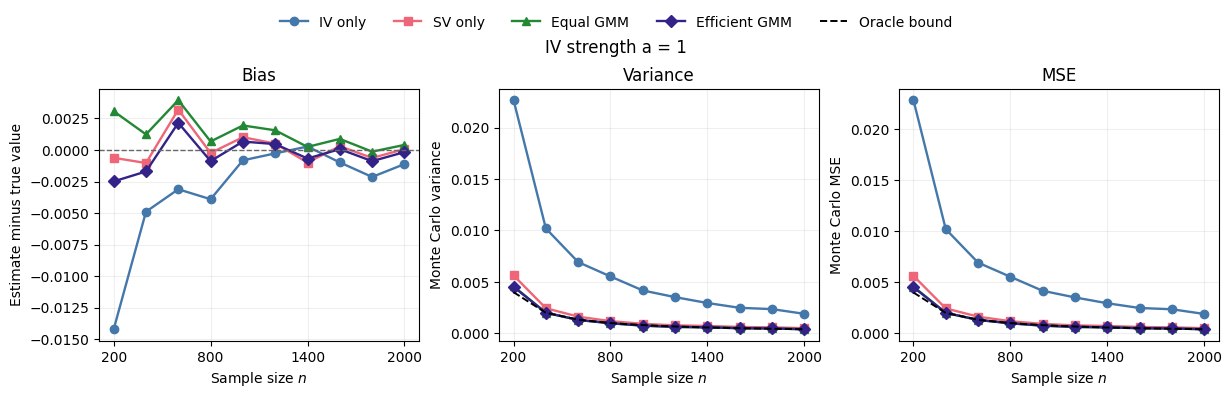

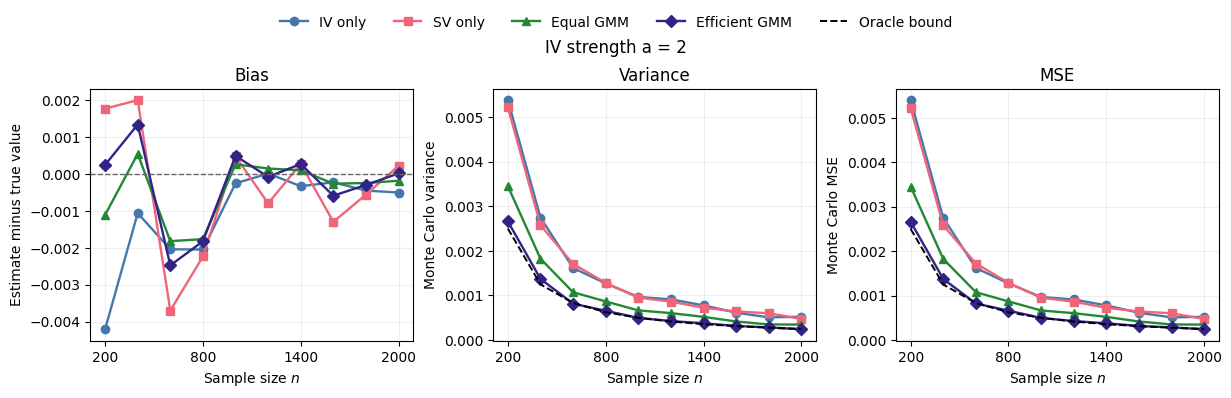

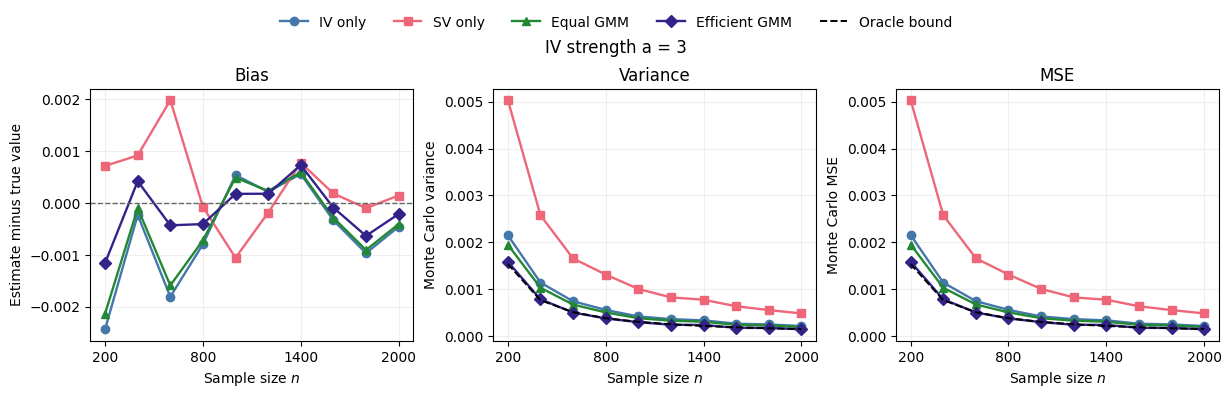

In [3]:
for a, a_name, filename in zip(a_values, a_names, ["a1", "a2", "a3"]):
    data = metrics[np.isclose(metrics["a"], a)]
    fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.3), constrained_layout=True)
    for method in methods:
        part = data[data["method"] == method].sort_values("n")
        for ax, measure in zip(axes, ["bias", "variance", "mse"]):
            ax.plot(part["n"], part[measure], marker=markers[method],
                    color=colors[method], linewidth=1.7, label=labels[method])
    axes[0].axhline(0, color="0.4", linestyle="--", linewidth=1)
    for ax in axes[1:]:
        ax.plot(n_values,
                4 / ((a**2 + 4) * np.array(n_values)),
                color="black", linestyle="--", linewidth=1.4, label="Oracle bound")
    for ax, title in zip(axes, ["Bias", "Variance", "MSE"]):
        ax.set_title(title)
        ax.set_xlabel("Sample size $n$")
        ax.set_xticks([200, 800, 1400, 2000])
        ax.grid(alpha=0.2)
    axes[0].set_ylabel("Estimate minus true value")
    axes[1].set_ylabel("Monte Carlo variance")
    axes[2].set_ylabel("Monte Carlo MSE")
    handles, legend_labels = axes[2].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 1.18),
               ncol=5, frameon=False)
    fig.suptitle(f"IV strength a = {a_name}", y=1.07, fontsize=12)
    fig.savefig(result_dir / f"efficiency_{filename}.pdf", bbox_inches="tight")
    fig.savefig(result_dir / f"efficiency_{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()


## Compact summaries for each value of $a$

The table compares feasible efficient GMM with whichever single-channel method has the smaller MSE at that same $(a,n)$. The “MSE gain” is relative to that best single channel. Squared bias, variance, and MSE are reported separately so the source of the gain is visible. Full results for every method and $n$ are saved in `result/efficiency_decomposition.csv`.


In [4]:
story_rows = []
for a, a_name in zip(a_values, a_names):
    for n in n_values:
        part = metrics[np.isclose(metrics["a"], a) & (metrics["n"] == n)].set_index("method")
        best_single = min(["iv", "sv"], key=lambda method: part.loc[method, "mse"])
        efficient = part.loc["feasible_efficient"]
        story_rows.append({
            "a": a, "n": n, "best_single": labels[best_single],
            "best_single_mse": part.loc[best_single, "mse"],
            "efficient_bias": efficient["bias"],
            "efficient_bias_squared": efficient["bias_squared"],
            "efficient_variance": efficient["variance"],
            "efficient_mse": efficient["mse"],
            "mse_gain": 1 - efficient["mse"] / part.loc[best_single, "mse"],
        })
story = pd.DataFrame(story_rows)
story.to_csv(result_dir / "efficiency_story_summary.csv", index=False)
for a, a_name in zip(a_values, a_names):
    print(f"a = {a_name}")
    part = story[np.isclose(story["a"], a)].drop(columns="a").set_index("n")
    display(part.style.format({
        "best_single_mse": "{:.5f}", "efficient_bias": "{:+.5f}",
        "efficient_bias_squared": "{:.6f}", "efficient_variance": "{:.5f}",
        "efficient_mse": "{:.5f}", "mse_gain": "{:.1%}",
    }))


a = 1


,best_single,best_single_mse,efficient_bias,efficient_bias_squared,efficient_variance,efficient_mse,mse_gain
n,,,,,,,
200,SV only,0.00564,-0.00249,0.000006,0.00452,0.00452,19.8%
400,SV only,0.00244,-0.00170,0.000003,0.00200,0.00201,17.9%
600,SV only,0.00163,+0.00216,0.000005,0.00130,0.00131,20.1%
800,SV only,0.00119,-0.00088,0.000001,0.00098,0.00098,17.2%
1000,SV only,0.00093,+0.00067,0.000000,0.00075,0.00075,18.9%
1200,SV only,0.00078,+0.00047,0.000000,0.00063,0.00063,19.2%
1400,SV only,0.00072,-0.00068,0.000000,0.00058,0.00059,18.6%
1600,SV only,0.00062,+0.00007,0.000000,0.00050,0.00050,19.6%
1800,SV only,0.00058,-0.00088,0.000001,0.00048,0.00048,17.8%


a = 2


,best_single,best_single_mse,efficient_bias,efficient_bias_squared,efficient_variance,efficient_mse,mse_gain
n,,,,,,,
200,SV only,0.00522,+0.00024,0.000000,0.00266,0.00266,49.0%
400,SV only,0.00258,+0.00134,0.000002,0.00137,0.00137,46.8%
600,IV only,0.00162,-0.00248,0.000006,0.00082,0.00082,49.2%
800,IV only,0.00127,-0.00183,0.000003,0.00066,0.00066,48.2%
1000,SV only,0.00095,+0.00049,0.000000,0.00050,0.00050,47.6%
1200,SV only,0.00086,-0.00008,0.000000,0.00043,0.00043,50.6%
1400,SV only,0.00073,+0.00027,0.000000,0.00038,0.00038,48.0%
1600,IV only,0.00061,-0.00059,0.000000,0.00032,0.00032,48.4%
1800,IV only,0.00051,-0.00030,0.000000,0.00028,0.00028,44.1%


a = 3


,best_single,best_single_mse,efficient_bias,efficient_bias_squared,efficient_variance,efficient_mse,mse_gain
n,,,,,,,
200,IV only,0.00216,-0.00116,0.000001,0.00159,0.00159,26.4%
400,IV only,0.00114,+0.00042,0.000000,0.00079,0.00079,31.1%
600,IV only,0.00075,-0.00043,0.000000,0.00051,0.00051,32.4%
800,IV only,0.00056,-0.00041,0.000000,0.00038,0.00038,32.3%
1000,IV only,0.00042,+0.00017,0.000000,0.00030,0.00030,28.8%
1200,IV only,0.00037,+0.00018,0.000000,0.00025,0.00025,33.0%
1400,IV only,0.00034,+0.00073,0.000001,0.00024,0.00024,28.7%
1600,IV only,0.00027,-0.00009,0.000000,0.00018,0.00018,33.0%
1800,IV only,0.00025,-0.00064,0.000000,0.00018,0.00018,29.8%


## Main-paper summary table

At the representative sample size $n=1000$, the table puts empirical $n\times\mathrm{MSE}$ next to the oracle efficient asymptotic variance. The bound is a benchmark for efficient GMM, not the theoretical variance of equal-weight GMM. For equal weighting, the correct asymptotic variance is $(a^6/4+1)/(a^4/4+1)^2$, equal to 0.80, 0.68, and 0.41 for $a=1,2,3$. The gain column compares efficient GMM with the lower-MSE single channel.


In [5]:
main_rows = []
for a, a_name in zip(a_values, a_names):
    part = metrics[np.isclose(metrics["a"], a) & (metrics["n"] == 1000)].set_index("method")
    best_single = min(part.loc["iv", "mse"], part.loc["sv", "mse"])
    main_rows.append({
        "a": a_name,
        "iv_scaled_mse": 1000 * part.loc["iv", "mse"],
        "sv_scaled_mse": 1000 * part.loc["sv", "mse"],
        "equal_scaled_mse": 1000 * part.loc["equal", "mse"],
        "efficient_scaled_mse": 1000 * part.loc["feasible_efficient", "mse"],
        "oracle_efficient_bound": 4 / (a**2 + 4),
        "mse_gain_vs_best_single": 1 - part.loc["feasible_efficient", "mse"] / best_single,
    })
main_table = pd.DataFrame(main_rows).set_index("a")
main_table.to_csv(result_dir / "efficiency_main_table.csv")
display(main_table.style.format({
    "iv_scaled_mse": "{:.3f}", "sv_scaled_mse": "{:.3f}",
    "equal_scaled_mse": "{:.3f}", "efficient_scaled_mse": "{:.3f}",
    "oracle_efficient_bound": "{:.3f}", "mse_gain_vs_best_single": "{:.1%}",
}))


,iv_scaled_mse,sv_scaled_mse,equal_scaled_mse,efficient_scaled_mse,oracle_efficient_bound,mse_gain_vs_best_single
a,,,,,,
1,4.170,0.926,0.753,0.751,0.800,18.9%
2,0.968,0.951,0.666,0.498,0.500,47.6%
3,0.423,1.010,0.386,0.301,0.308,28.8%


## Type I error and local power

Under $H_0:\beta=0$, the rejection frequency of the two-sided 5% Wald test is the empirical Type I error. The dashed line marks the nominal 5% level. Under the local alternative $\beta=2/\sqrt n$, the same rejection frequency is power. These scenarios were simulated separately from the $\beta=1$ estimation results above. With 1,000 replications, a 5% rejection rate has Monte Carlo standard error about 0.007, so small deviations from 0.05 are expected.


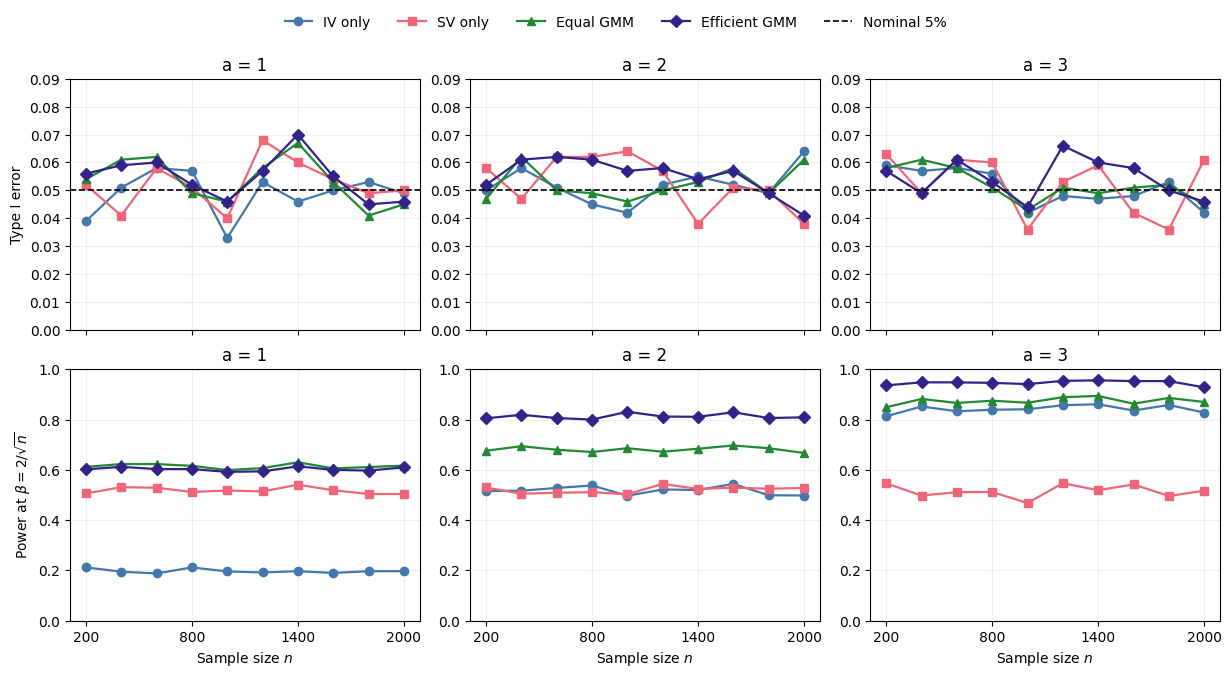

In [6]:
inference = raw[raw["scenario"].isin(["size", "power_1", "power_2"])].groupby(
    ["scenario", "a", "n", "method"], as_index=False
).agg(
    replications=("reject_h0_beta_0", "size"),
    rejection_rate=("reject_h0_beta_0", "mean"),
    coverage=("covered", "mean"),
)
inference.to_csv(result_dir / "efficiency_inference_summary.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(12.2, 6.2), sharex=True, constrained_layout=True)
for col, (a, a_name) in enumerate(zip(a_values, a_names)):
    for row, scenario in enumerate(["size", "power_2"]):
        ax = axes[row, col]
        data = inference[(inference["scenario"] == scenario) & np.isclose(inference["a"], a)]
        for method in methods:
            part = data[data["method"] == method].sort_values("n")
            ax.plot(part["n"], part["rejection_rate"], marker=markers[method],
                    color=colors[method], linewidth=1.6, label=labels[method])
        if row == 0:
            ax.axhline(0.05, color="black", linestyle="--", linewidth=1.2, label="Nominal 5%")
        ax.set_title(f"a = {a_name}")
        ax.set_xticks([200, 800, 1400, 2000])
        ax.grid(alpha=0.2)
        ax.set_ylim(0, 0.09 if row == 0 else 1.0)
        if row == 1:
            ax.set_xlabel("Sample size $n$")
axes[0, 0].set_ylabel("Type I error")
axes[1, 0].set_ylabel(r"Power at $\beta=2/\sqrt{n}$")
handles, legend_labels = axes[0, 2].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 1.08),
           ncol=5, frameon=False)
fig.savefig(result_dir / "efficiency_inference.pdf", bbox_inches="tight")
fig.savefig(result_dir / "efficiency_inference.png", dpi=300, bbox_inches="tight")
plt.show()


The compact table below pairs Type I error and local power for efficient GMM with the best single channel from the MSE comparison. The full inference CSV also contains the $\beta=1/\sqrt n$ power scenario and all methods.


In [7]:
infer_rows = []
for _, item in story.iterrows():
    a, n = item["a"], item["n"]
    best_method = "iv" if item["best_single"] == "IV only" else "sv"
    part = inference[np.isclose(inference["a"], a) & (inference["n"] == n)]
    rates = part.pivot(index="method", columns="scenario", values="rejection_rate")
    infer_rows.append({
        "a": a, "n": n,
        "efficient_type_i": rates.loc["feasible_efficient", "size"],
        "efficient_power_1": rates.loc["feasible_efficient", "power_1"],
        "efficient_power_2": rates.loc["feasible_efficient", "power_2"],
        "best_single": item["best_single"],
        "best_single_power_2": rates.loc[best_method, "power_2"],
    })
infer_table = pd.DataFrame(infer_rows)
infer_table.to_csv(result_dir / "efficiency_inference_story_summary.csv", index=False)
for a, a_name in zip(a_values, a_names):
    print(f"a = {a_name}")
    display(infer_table[np.isclose(infer_table["a"], a)].drop(columns="a").set_index("n").style.format({
        "efficient_type_i": "{:.3f}", "efficient_power_1": "{:.3f}",
        "efficient_power_2": "{:.3f}", "best_single_power_2": "{:.3f}",
    }))


a = 1


,efficient_type_i,efficient_power_1,efficient_power_2,best_single,best_single_power_2
n,,,,,
200,0.056,0.211,0.602,SV only,0.506
400,0.059,0.206,0.612,SV only,0.531
600,0.060,0.215,0.603,SV only,0.529
800,0.052,0.209,0.603,SV only,0.512
1000,0.046,0.183,0.592,SV only,0.518
1200,0.057,0.233,0.594,SV only,0.514
1400,0.070,0.229,0.614,SV only,0.541
1600,0.055,0.192,0.600,SV only,0.519
1800,0.045,0.197,0.597,SV only,0.504


a = 2


,efficient_type_i,efficient_power_1,efficient_power_2,best_single,best_single_power_2
n,,,,,
200,0.052,0.326,0.805,SV only,0.530
400,0.061,0.335,0.819,SV only,0.505
600,0.062,0.302,0.806,IV only,0.528
800,0.061,0.294,0.800,IV only,0.538
1000,0.057,0.300,0.831,SV only,0.503
1200,0.058,0.315,0.812,SV only,0.544
1400,0.054,0.310,0.811,SV only,0.524
1600,0.057,0.317,0.829,IV only,0.544
1800,0.049,0.293,0.806,IV only,0.499


a = 3


,efficient_type_i,efficient_power_1,efficient_power_2,best_single,best_single_power_2
n,,,,,
200,0.057,0.465,0.936,IV only,0.813
400,0.049,0.447,0.948,IV only,0.852
600,0.061,0.458,0.948,IV only,0.833
800,0.053,0.455,0.946,IV only,0.839
1000,0.044,0.431,0.941,IV only,0.841
1200,0.066,0.452,0.954,IV only,0.857
1400,0.060,0.431,0.956,IV only,0.861
1600,0.058,0.444,0.953,IV only,0.836
1800,0.050,0.433,0.953,IV only,0.858


## Main points for the paper

- **$a=1$ (SV is stronger):** IV-only has the highest MSE. Efficient GMM improves on SV-only at every $n$.
- **$a=2$ (balanced):** IV and SV have equal asymptotic variances; efficient GMM combines their complementary information.
- **$a=3$ (IV is stronger):** IV-only becomes more precise than SV-only, while efficient GMM can still gain from combining both channels.

The null rejection rates remain close to 5% across designs, while efficient GMM has higher power than the best single channel at all 30 design points for $\beta=2/\sqrt n$. Because the alternatives scale as $1/\sqrt n$, power need not rise with $n$ in these plots.

In all three regimes, bias is small relative to the standard deviation and the MSE pattern is driven mainly by variance. The theoretical curve is an asymptotic population benchmark, so finite-sample points need not lie on it. These conclusions apply to sample-estimated projections under correct specification.

The three figures are saved as PDF and PNG files in `result/`, along with English-named CSV summaries. The full replication-level and original summary CSVs are retained for further analysis.

**Theory note.** Under the sample-projection estimator in (3.3), the SV first-order score in (3.5) is $v\epsilon$ for this DGP. Hence $V_{\mathrm{SV}}=1$ and the efficient combined benchmark is $4/(a^2+4)$; the equal-information case is $a=2$. Section 5.1 of the PDF instead states $V_{\mathrm{SV}}=2$ and $4/(a^2+2)$, which correspond to using the population residual $v$ directly with the unresidualized disturbance $u+\epsilon$. The sample-projection experiment uses the former benchmarks.

**File note.** `result/efficiency_main.pdf`, `result/efficiency_main.png`, and the `efficiency_a_sqrt2` files are older figures from previous designs. They are retained but are not part of this notebook or the current sample-projection results. Use `efficiency_a1`, `efficiency_a2`, `efficiency_a3`, and `efficiency_inference` for the current figures.
